# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.


## Setup

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [113]:
# GIVEN — run as-is
# Card & Krueger (1994), from David Card's own archive
import io
import re
import ssl
import urllib.request
import zipfile

# bypass the site certificate problem for this one download
ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip",
    timeout=60,
    context=ctx
).read()

z = zipfile.ZipFile(io.BytesIO(raw))
print(z.namelist())

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

# GIVEN — run as-is
# The two-by-two, by hand: mean employment by state, before and after
means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]    # STATE is 1 for New Jersey, 0 for Pennsylvania

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"{'':<12}{'before':>9}{'after':>9}{'change':>9}")
print("-" * 39)
print(f"{'NJ (treated)':<12}{nj.fte_before:>9.2f}{nj.fte_after:>9.2f}"
      f"{nj.fte_after - nj.fte_before:>9.2f}")
print(f"{'PA (control)':<12}{pa.fte_before:>9.2f}{pa.fte_after:>9.2f}"
      f"{pa.fte_after - pa.fte_before:>9.2f}")
print("-" * 39)
print(f"{'DiD':<12}{'':>18}{did:>9.2f}")

['check.sas', 'codebook', 'public.dat', 'read.me', 'survey1.nj', 'survey2.nj']
410 restaurants: 331 NJ, 79 PA
               before    after   change
---------------------------------------
NJ (treated)    20.44    21.03     0.59
PA (control)    23.33    21.17    -2.17
---------------------------------------
DiD                                2.75


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [114]:
ck_long = ck.melt(
    id_vars=["STATE"],
    value_vars=["fte_before", "fte_after"],
    var_name="wave",
    value_name="fte"
)

ck_long["treated"] = (ck_long["STATE"] == 1).astype(int)
ck_long["post"] = (ck_long["wave"] == "fte_after").astype(int)

usable = ck_long.dropna(subset=["fte"])

X = np.column_stack([
    np.ones(len(usable)),
    usable["treated"].to_numpy(),
    usable["post"].to_numpy(),
    (usable["treated"] * usable["post"]).to_numpy()
])
y = usable["fte"].to_numpy()

coefficients, residuals, rank, singular_values = np.linalg.lstsq(X, y, rcond=None)

print("intercept, treated, post, interaction:", coefficients)
print(f"DiD interaction: {coefficients[3]:.2f} FTE")

intercept, treated, post, interaction: [23.33116883 -2.89176073 -2.16558442  2.75360578]
DiD interaction: 2.75 FTE


*Your answer here.*

The intercept is the Pennsylvania mean before the policy. The treated coefficient is the pre-policy difference between New Jersey and Pennsylvania, and the post coefficient is the before-to-after change in Pennsylvania. Neither is the policy effect by itself. The interaction coefficient measures how much more employment changed in New Jersey than in Pennsylvania; it reproduces the DiD estimate of 2.75 FTE.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [115]:
import statsmodels.formula.api as smf

#constants 
n_boards = 8 
n_counties = 5 
years = np.arange(1, 13)

adoption_years = { 1: 3, 2: 3, 3: 4, 4: 4, 5: 5, 6: 5, 7: 6, 8: None }

effect_growth_per_exposure_year = 1.0
board_shock_sd = 2.0
county_noise_sd = 1.0

# generate the setup
county_baselines = rng.normal(0, 1.5, size=n_boards * n_counties)
year_effects = np.linspace(0, 2, len(years))
board_shocks = rng.normal(0, board_shock_sd, size = (n_boards, len(years)))

rows = []
county_number = 0

for board in range(1, n_boards + 1):
    adoption = adoption_years[board]

    for _ in range(n_counties):
        county_number += 1

        for year_index, year in enumerate(years):
            treated = int(adoption is not None and year >= adoption)
            exposure = year - adoption + 1 if treated else 0
            true_effect = effect_growth_per_exposure_year * exposure

            outcome = (
                10
                + county_baselines[county_number - 1]
                + year_effects[year_index]
                + board_shocks[board - 1, year_index]
                + true_effect
                + rng.normal(0, county_noise_sd)
            )

            rows.append({
                "board": board,
                "county": county_number,
                "year": year,
                "adoption_year": adoption,
                "treated": treated,
                "exposure": exposure,
                "true_effect": true_effect,
                "outcome": outcome
            })

panel = pd.DataFrame(rows)

panel["g"] = panel["adoption_year"].fillna(10**9).astype(int)
panel["t"] = panel["year"]


# twfe = county fixed effects + year fixed effects + one treatment coefficient.
twfe = smf.ols(
    "outcome ~ treated + C(county) + C(year)",
    data=panel
).fit()

true_att = panel.loc[panel["treated"] == 1, "true_effect"].mean()
twfe_estimate = twfe.params["treated"]


# print the panel 
print(f"Panel: {panel['county'].nunique()} counties, "
      f"{panel['board'].nunique()} boards, {panel['year'].nunique()} years, "
      f"{len(panel)} county-years")
print("Adoption years by board:", adoption_years)
print(f"Effect growth per exposure year: {effect_growth_per_exposure_year:.2f}")
print(f"Board-shock variance: {board_shock_sd**2:.2f}")
print(f"True average effect on treated county-years: {true_att:.3f}")
print(f"TWFE treatment estimate: {twfe_estimate:.3f}")
print(f"TWFE minus true average effect: {twfe_estimate - true_att:.3f}")


Panel: 40 counties, 8 boards, 12 years, 480 county-years
Adoption years by board: {1: 3, 2: 3, 3: 4, 4: 4, 5: 5, 6: 5, 7: 6, 8: None}
Effect growth per exposure year: 1.00
Board-shock variance: 4.00
True average effect on treated county-years: 4.918
TWFE treatment estimate: 1.806
TWFE minus true average effect: -3.112


*Your answer here.*

The panel contains 40 counties across 8 boards, observed for 12 years, giving 480 county-year observations. The planted average treatment effect across treated county-years is 4.92. The two-way fixed-effects, TWFE, estimate is 1.806, about 3.11 below that average. This gap is concerning and means we should examine which comparisons TWFE uses in the staggered rollout.

### Step 2.2: Decompose it (15 pts)

In [116]:
NEVER = 10**9
times = np.sort(panel["t"].unique())
cohorts = sorted(panel.loc[panel["g"] < NEVER, "g"].unique())


D = panel.pivot(index="county", columns="t", values="treated").to_numpy(dtype=float)
D_tilde = (
    D
    - D.mean(axis=1, keepdims=True)
    - D.mean(axis=0, keepdims=True)
    + D.mean()
)
V = np.mean(D_tilde**2)

# cohort shares and average treatment exposure
unit_cohorts = panel.drop_duplicates("county").set_index("county")["g"]
shares = unit_cohorts.value_counts(normalize=True).to_dict()
never_share = shares.get(NEVER, 0.0)
treated_share = {g: np.mean(times >= g) for g in cohorts}

#mean change for each cohort
cohort_means = panel.groupby(["g", "t"])["outcome"].mean().unstack()

def mean_change(g, before, after):
    """Mean outcome after minus mean outcome before for cohort g."""
    return (
        cohort_means.loc[g, times[after]].mean()
        - cohort_means.loc[g, times[before]].mean()
    )

rows = []


#treated vs never-treated comparisons
for k in cohorts:
    nk = shares[k]
    if never_share > 0:
        p = nk / (nk + never_share)
        weight = (
            (nk + never_share)**2
            * p * (1 - p)
            * treated_share[k] * (1 - treated_share[k])
            / V
        )

        before = times < k
        after = times >= k
        estimate = (
            mean_change(k, before, after)
            - mean_change(NEVER, before, after)
        )
        rows.append({
            "treated_cohort": k,
            "control_cohort": "Never-treated",
            "comparison": "Treated vs never-treated",
            "estimate": estimate,
            "weight": weight,
        })


# clean and already-treated comparisons
for i, k in enumerate(cohorts):
    for l in cohorts[i + 1:]: 
        nk, nl = shares[k], shares[l]
        p = nk / (nk + nl)
        base = (nk + nl)**2 * p * (1 - p) / V
        Dk, Dl = treated_share[k], treated_share[l]

        # clean comparison
        before = times < k
        after = (times >= k) & (times < l)
        clean_estimate = (
            mean_change(k, before, after)
            - mean_change(l, before, after)
        )
        clean_weight = base * (Dk - Dl) * (1 - Dk)
        rows.append({
            "treated_cohort": k,
            "control_cohort": l,
            "comparison": "Not-yet-treated control",
            "estimate": clean_estimate,
            "weight": clean_weight,
        })

        # already treated comparison
        before = (times >= k) & (times < l)
        after = times >= l
        forbidden_estimate = (
            mean_change(l, before, after)
            - mean_change(k, before, after)
        )
        forbidden_weight = base * Dl * (Dk - Dl)
        rows.append({
            "treated_cohort": l,
            "control_cohort": k,
            "comparison": "Already-treated control",
            "estimate": forbidden_estimate,
            "weight": forbidden_weight,
        })

decomposition = pd.DataFrame(rows)

# normalize and check agains the twfe estimate
decomposition["weight"] /= decomposition["weight"].sum()
decomposition["weighted_contribution"] = (
    decomposition["estimate"] * decomposition["weight"]
)
weighted_sum = decomposition["weighted_contribution"].sum()
already_treated_weight = decomposition.loc[
    decomposition["comparison"] == "Already-treated control", "weight"
].sum()


#print results
print(decomposition.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nNumber of comparisons: {len(decomposition)}")
print(f"Weights sum to: {decomposition['weight'].sum():.6f}")
print(f"Weighted sum of 2x2 estimates: {weighted_sum:.3f}")
print(f"TWFE treatment estimate: {twfe.params['treated']:.3f}")
print(
    "Weight on comparisons using already-treated controls: "
    f"{already_treated_weight:.3f} ({already_treated_weight:.1%})"
)

true_effects = panel.loc[panel["treated"] == 1, "true_effect"]
print(
    "Planted-effect range among treated county-years: "
    f"{true_effects.min():.3f} to {true_effects.max():.3f}"
)
print(
    "TWFE below the minimum planted effect:",
    twfe.params["treated"] < true_effects.min()
)


 treated_cohort control_cohort               comparison  estimate  weight  weighted_contribution
              3  Never-treated Treated vs never-treated    7.6912  0.0839                 0.6450
              4  Never-treated Treated vs never-treated    7.1605  0.1132                 0.8106
              5  Never-treated Treated vs never-treated    4.5407  0.1342                 0.6092
              6  Never-treated Treated vs never-treated    7.1595  0.0734                 0.5253
              3              4  Not-yet-treated control    0.0010  0.0168                 0.0000
              4              3  Already-treated control   -1.9554  0.0755                -0.1476
              3              5  Not-yet-treated control    1.1686  0.0335                 0.0392
              5              3  Already-treated control   -3.0593  0.1342                -0.4105
              3              6  Not-yet-treated control   -0.5328  0.0252                -0.0134
              6              3

*Your answer here.*
The decomposition expresses TWFE as a weighted average of 16 two-by-two comparisons. The weights sum to 1, and their weighted estimates reproduce the TWFE estimate of 1.806. Comparisons using already-treated counties as controls receive 45.3% of the total weight. With treatment effects growing over time, these comparisons become inaccurate when the control has had teh treament longer than the "treatment group"

The TWFE estimate is within the planted-effect range of 1 to 10. That doesnt get rid of the concern that the estimate still combines comparisons that do not all represent a clean untreated control group.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [117]:
NEVER = 10**9

def clean_att(panel):
    out = []
    for g in sorted(panel.loc[panel["g"] < NEVER, "g"].unique()):
        cohort = panel[panel["g"] == g]
        for t in range(g, panel["t"].max() + 1):
            controls = panel[panel["g"] > t]
            if controls.empty:
                continue
            d_tr = (cohort.loc[cohort["t"] == t, "outcome"].mean()
                    - cohort.loc[cohort["t"] == g - 1, "outcome"].mean())
            d_co = (controls.loc[controls["t"] == t, "outcome"].mean()
                    - controls.loc[controls["t"] == g - 1, "outcome"].mean())
            n = (cohort["t"] == t).sum()
            out.append({"g": g, "t": t, "att": d_tr - d_co, "n": n})
    cells = pd.DataFrame(out)
    att_hat = np.average(cells["att"], weights=cells["n"])
    return cells, att_hat
 
per_cell,att_hat = clean_att(panel)

print(f"{'estimator':<38}{'estimate':>10}{'truth':>9}")
print("-" * 57)
print(
    f"{'TWFE (all comparisons)':<38}"
    f"{twfe.params['treated']:>10.2f}{true_att:>9.2f}"
)
print(
    f"{'Not-yet-treated controls only':<38}"
    f"{att_hat:>10.2f}{true_att:>9.2f}"
)

estimator                               estimate    truth
---------------------------------------------------------
TWFE (all comparisons)                      1.81     4.92
Not-yet-treated controls only               4.99     4.92


*Your answer here.*
the not yet treated estimate is 4.99 which is very close to the true ATT of 4.92. in comparison the TWFE estimate is only 1.81, which significantly underestimates the true effect. The not-yet-treated approach avoids using already-treated counties as controls, which can cause problems when treatment effects grow over time. This aproach still assumeds that the treated and not yet treated counties would have similar trends if both were never treated. So, while the estimate is closer to the true ATT in this simulation, it still depends on these assumptions being true. 

### Step 3.2: The assumption you cannot test (12 pts)

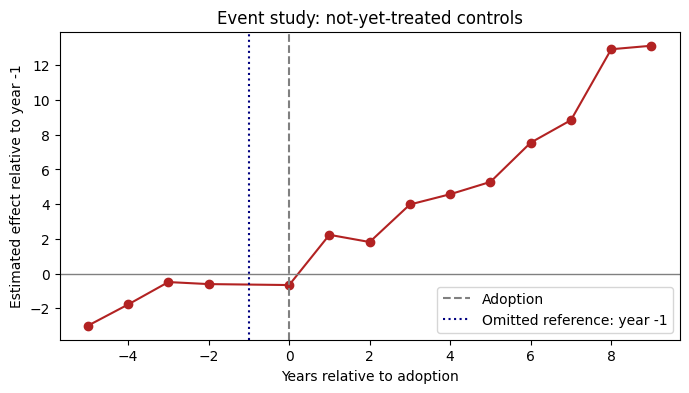

In [118]:
event_rows = []

for g in sorted(panel.loc[panel["g"] < NEVER, "g"].unique()):
    cohort = panel[panel["g"] == g]
    baseline = g - 1

    for t in sorted(panel["t"].unique()):
        if t == baseline:
            continue  

        controls = panel[panel["g"] > max(t, baseline)]
        if controls.empty:
            continue

        d_tr = (
            cohort.loc[cohort["t"] == t, "outcome"].mean()
            - cohort.loc[cohort["t"] == baseline, "outcome"].mean()
        )
        d_co = (
            controls.loc[controls["t"] == t, "outcome"].mean()
            - controls.loc[controls["t"] == baseline, "outcome"].mean()
        )

        event_rows.append({
            "event_time": t - g,
            "estimate": d_tr - d_co,
            "n": cohort.loc[cohort["t"] == t, "county"].nunique(),
        })

event_cells = pd.DataFrame(event_rows)
event_study = (
    event_cells.groupby("event_time")
    .apply(lambda x: np.average(x["estimate"], weights=x["n"]))
    .rename("estimate")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    event_study["event_time"],
    event_study["estimate"],
    marker="o",
    color="firebrick",
)
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(0, color="grey", linestyle="--", label="Adoption")
ax.axvline(-1, color="navy", linestyle=":", label="Omitted reference: year -1")
ax.set_xlabel("Years relative to adoption")
ax.set_ylabel("Estimated effect relative to year -1")
ax.set_title("Event study: not-yet-treated controls")
ax.legend()
plt.show()


*Your answer here.*

The pre-treatment estimates are below zero instead of flat around zero, raising concerns that treated and untreated counties had different trends before the policy. Post-treatment estimates are mostly positive and rise over time, suggesting effects may grow with exposure. However, without confidence intervals, we can't tell how precise these estimates are. The event study can show possible problems with parallel trends, but it cannot prove the assumption.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [119]:
county_clustered = twfe.get_robustcov_results(
    cov_type="cluster",
    groups=panel["county"],
)
board_clustered = twfe.get_robustcov_results(
    cov_type="cluster",
    groups=panel["board"],
)

treated_idx = twfe.model.exog_names.index("treated")
estimate = twfe.params["treated"]

print(f"Treatment estimate:          {estimate:.3f}")
print(f"Default standard error:      {twfe.bse['treated']:.3f}")
print(f"County-clustered SE:         {county_clustered.bse[treated_idx]:.3f}")
print(f"Board-clustered SE:          {board_clustered.bse[treated_idx]:.3f}")


Treatment estimate:          1.806
Default standard error:      0.453
County-clustered SE:         1.003
Board-clustered SE:          2.308


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [120]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit (ECON 5200 PS3), extending Lab 11's did_utils.py."""
from __future__ import annotations
import numpy as np
import pandas as pd

NEVER = 10**9

# Lab 11's functions, carried over
def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """The canonical 2x2: difference of differences of the four group means."""
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average the ATT(g, t) cells by event time e = t - g, weighted by size.

    Negative e would be pre-treatment periods. They are a diagnostic, not a
    test: estimates near zero are consistent with parallel trends and do not
    establish it.
    """
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({"e": e, "att": np.average(group["att"], weights=group["n"])})
    return pd.DataFrame(rows)

# your clustered-inference wrapper (Step 3.3)
def clustered_inference(model, panel, cluster="board"):
    """Return model results with standard errors clustered by a panel column."""
    if cluster not in panel.columns:
        raise ValueError(f"Cluster column {cluster!r} is not in the panel.")

    return model.get_robustcov_results(
        cov_type="cluster",
        groups=panel[cluster],
    )


# your bootstrap (Task 4.1)
def clean_att(panel):
    rows = []
    for g in sorted(panel.loc[panel["g"] < NEVER, "g"].unique()):
        cohort = panel[panel["g"] == g]
        baseline = g - 1
        for t in sorted(panel["t"].unique()):
            if t < g:
                continue
            controls = panel[panel["g"] > t]
            if controls.empty:
                continue

            treated_change = (
                cohort.loc[cohort["t"] == t, "outcome"].mean()
                - cohort.loc[cohort["t"] == baseline, "outcome"].mean()
            )
            control_change = (
                controls.loc[controls["t"] == t, "outcome"].mean()
                - controls.loc[controls["t"] == baseline, "outcome"].mean()
            )
            rows.append({
                "g": g,
                "t": t,
                "att": treated_change - control_change,
                "n": cohort.loc[cohort["t"] == t, "county"].nunique(),
            })

    cells = pd.DataFrame(rows)
    if cells.empty or cells["att"].isna().any():
        raise ValueError("No valid ATT cells.")
    return cells, np.average(cells["att"], weights=cells["n"])

def bootstrap_clean_att(panel, n_boot=999, seed=42, cluster="board"):
    if cluster not in panel.columns:
        raise ValueError(f"Cluster column {cluster!r} is not in the panel.")
    if n_boot < 1:
        raise ValueError("n_boot must be at least 1.")

    _, estimate = clean_att(panel)
    cluster_ids = panel[cluster].drop_duplicates().to_numpy()
    rng = np.random.default_rng(seed)
    draws = []

    for _ in range(n_boot):
        sampled_ids = rng.choice(cluster_ids, size=len(cluster_ids), replace=True)
        pieces = []
        for draw_id, original_id in enumerate(sampled_ids):
            piece = panel.loc[panel[cluster] == original_id].copy()
            piece[cluster] = draw_id
            piece["county"] = piece["county"].map(
                lambda county: f"{draw_id}_{county}"
            )
            pieces.append(piece)

        try:
            _, draw_estimate = clean_att(pd.concat(pieces, ignore_index=True))
            if np.isfinite(draw_estimate):
                draws.append(draw_estimate)
        except ValueError:
            continue

    if not draws:
        raise RuntimeError("No valid bootstrap samples; check the panel.")

    draws = np.asarray(draws)
    return {
        "estimate": estimate,
        "draws": draws,
        "ci_95": np.percentile(draws, [2.5, 97.5]),
        "n_successful": len(draws),
    }

def wild_cluster_bootstrap(
    model,
    panel,
    n_boot=999,
    seed=42,
    cluster="board",
    treatment="treated"
):

    if cluster not in panel.columns:
        raise ValueError(f"Cluster column {cluster!r} is not in the panel.")

    if n_boot < 1:
        raise ValueError("n_boot must be at least 1.")

    if treatment not in model.params.index:
        raise ValueError(f"{treatment!r} is not a model coefficient.")

    # Original estimate and standard error
    observed_estimate = model.params[treatment]

    observed_clustered = model.get_robustcov_results(
        cov_type="cluster",
        groups=panel[cluster]
    )

    treatment_idx = model.model.exog_names.index(treatment)
    observed_se = observed_clustered.bse[treatment_idx]
    observed_t = observed_estimate / observed_se

    # Fit the restricted model under H0: treatment effect = 0
    restricted_formula = model.model.formula
    restricted_formula = restricted_formula.replace(
        f"+ {treatment}", ""
    ).replace(
        f"{treatment} + ", ""
    )

    import statsmodels.formula.api as smf

    restricted_model = smf.ols(
        restricted_formula,
        data=panel
    ).fit()

    fitted_null = restricted_model.fittedvalues.to_numpy()
    residuals_null = restricted_model.resid.to_numpy()

    cluster_ids = panel[cluster].to_numpy()
    unique_clusters = np.unique(cluster_ids)

    rng = np.random.default_rng(seed)
    bootstrap_t = []

    for _ in range(n_boot):

        # One random weight per board
        weights = dict(zip(
            unique_clusters,
            rng.choice([-1, 1], size=len(unique_clusters))
        ))

        wild_weights = np.array([
            weights[c] for c in cluster_ids
        ])

        # Generate bootstrap outcome under the null
        bootstrap_panel = panel.copy()
        bootstrap_panel["_wild_y"] = (
            fitted_null + residuals_null * wild_weights
        )

        # Refit the original model
        bootstrap_model = smf.ols(
            model.model.formula.replace(
                model.model.endog_names, "_wild_y"
            ),
            data=bootstrap_panel
        ).fit()

        bootstrap_clustered = bootstrap_model.get_robustcov_results(
            cov_type="cluster",
            groups=bootstrap_panel[cluster]
        )

        boot_estimate = bootstrap_model.params[treatment]
        boot_se = bootstrap_clustered.bse[
            bootstrap_model.model.exog_names.index(treatment)
        ]

        if boot_se > 0:
            bootstrap_t.append(boot_estimate / boot_se)

    bootstrap_t = np.asarray(bootstrap_t)

    p_value = (
        1 + np.sum(np.abs(bootstrap_t) >= abs(observed_t))
    ) / (len(bootstrap_t) + 1)

    return {
        "estimate": observed_estimate,
        "t_statistic": observed_t,
        "p_value": p_value,
        "bootstrap_t": bootstrap_t,
        "n_successful": len(bootstrap_t)
    }

if __name__ == "__main__":
    import statsmodels.formula.api as smf

    # Check the two-by-two helper.
    example = pd.DataFrame({
        "treated": [0, 0, 1, 1],
        "post": [0, 1, 0, 1],
        "outcome": [1.0, 2.0, 3.0, 6.0],
    })
    assert np.isclose(two_by_two(example, "outcome", "treated", "post"), 2.0)

    # Check clustered inference 
    rows = []
    for cluster_id in range(8):
        treated = int(cluster_id >= 4)
        for post in (0, 1):
            outcome = 1 + 3 * treated + 2 * post + 2 * treated * post
            rows.append({
                "cluster": cluster_id,
                "treated": treated,
                "post": post,
                "outcome": outcome,
            })

    cluster_example = pd.DataFrame(rows)
    fit = smf.ols(
        "outcome ~ treated + post + treated:post",
        data=cluster_example,
    ).fit()
    clustered = clustered_inference(fit, cluster_example, cluster="cluster")
    assert clustered.cov_type == "cluster"

    # Check the bootstrap 
    rows = []
    for board in range(8):
        g = 2 if board < 4 else NEVER
        for county_in_board in range(2):
            county = board * 2 + county_in_board
            for t in (1, 2, 3):
                treated = int(g < NEVER and t >= g)
                rows.append({
                    "board": board,
                    "county": county,
                    "g": g,
                    "t": t,
                    "outcome": 10 + county + t + 2 * treated,
                })

    panel_example = pd.DataFrame(rows)
    boot = bootstrap_clean_att(
        panel_example, n_boot=99, seed=42, cluster="board"
    )
    assert np.isclose(boot["estimate"], 2.0)
    assert boot["n_successful"] > 0

    print("did_toolkit smoke tests passed.")

Overwriting src/did_toolkit.py


In [121]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt

# prove it runs: call each function on your panel
print("2x2 DiD:", dt.two_by_two(panel.query("g in [3, @NEVER] and t in [2, 3]").assign(treated=lambda x: (x.g == 3).astype(int), post=lambda x: (x.t == 3).astype(int)), "outcome", "treated", "post"))
print("Board-clustered SE:", dt.clustered_inference(twfe, panel, "board").bse[twfe.model.exog_names.index("treated")])
print("Bootstrap:", dt.bootstrap_clean_att(panel, n_boot=199, seed=42, cluster="board")["ci_95"])

2x2 DiD: -2.281472925328
Board-clustered SE: 2.3084530871055478
Bootstrap: [-1.49436655  7.17031857]


*Your answer here.*
The pre-treatment estimates are below zero, which raises concerns about parallel trends. Post-treatment estimates are positive and grow over time, but without confidence intervals, we can't tell how reliable these patterns are.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [122]:
import itertools
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


def _cluster_t(y, X, groups, k):
    """Cluster-robust (CR1, statsmodels default) t-stat for exog column k."""
    res = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": groups})
    return res.params[k] / res.bse[k], res


def wild_cluster_bootstrap_enum(
    df,
    cluster,                                   # name of the cluster column, e.g. "board"
    formula="outcome ~ treated + C(county) + C(t)",
    treat="treated",
    tol=1e-10,
):
    """
    Wild cluster bootstrap-t, null imposed, Rademacher weights,
    full enumeration of the 2**G weight vectors.
    """
    # --- unrestricted model (fixed design; only y changes in the bootstrap)
    unr = smf.ols(formula, data=df).fit()
    X = unr.model.exog
    y = unr.model.endog
    k = unr.model.exog_names.index(treat)

    # cluster codes aligned with the rows the model actually used
    used = df.loc[unr.model.data.row_labels, cluster]
    codes, uniques = pd.factorize(used)
    G = len(uniques)

    t_actual, res_actual = _cluster_t(y, X, codes, k)

    # --- restricted model: same formula with the treatment term removed (beta = 0)
    rhs = [s.strip() for s in formula.split("~")[1].split("+")]
    restricted_formula = formula.split("~")[0].strip() + " ~ " + " + ".join(
        s for s in rhs if s != treat
    )
    rst = smf.ols(restricted_formula, data=df).fit()
    assert len(rst.resid) == len(y), "restricted/unrestricted rows differ"
    y_tilde = np.asarray(rst.fittedvalues)     # fitted values  (ỹ)
    u_tilde = np.asarray(rst.resid)            # residuals      (ũ)

    # --- enumerate all 2**G sign vectors, one weight per cluster
    t_star = np.empty(2 ** G)
    for j, w in enumerate(itertools.product([-1.0, 1.0], repeat=G)):
        w = np.asarray(w)
        y_star = y_tilde + w[codes] * u_tilde  # w_{b(i)} * ũ_i
        t_star[j], _ = _cluster_t(y_star, X, codes, k)

    p_boot = np.mean(np.abs(t_star) >= abs(t_actual) - tol)

    # --- conventional cluster-robust p-values for comparison
    p_naive_normal = float(res_actual.pvalues[k])           # statsmodels default: N(0,1)
    res_t = sm.OLS(y, X).fit(cov_type="cluster",
                             cov_kwds={"groups": codes}, use_t=True)
    p_naive_t = float(res_t.pvalues[k])                     # t(G-1)

    return {
        "coef": float(res_actual.params[k]),
        "t_actual": float(t_actual),
        "G": G,
        "n_weight_vectors": 2 ** G,
        "p_boot": float(p_boot),
        "p_naive_normal": p_naive_normal,
        "p_naive_t_G-1": p_naive_t,
        "t_star": t_star,
    }


out = wild_cluster_bootstrap_enum(panel, cluster="board")
print({k: v for k, v in out.items() if k != "t_star"})

{'coef': 1.8058829050157943, 't_actual': 0.7822913600033775, 'G': 8, 'n_weight_vectors': 256, 'p_boot': 0.921875, 'p_naive_normal': 0.4340433633392766, 'p_naive_t_G-1': 0.45968303348760464}


*Your answer here.*

The wild bootstrap p-value is 0.9219, compared to 0.4340 and 0.4597 using the other methods. All are above 0.05, so we don't have enough evidence to say the TWFE effect is different from zero. This doesn't mean the true effect is zero.

Since we only have 8 boards, there are 256 possible combinations of weights, so we can test all of them instead of randomly sampling. We apply weights by board because counties in the same board can share similar shocks. We also set the treatment effect to zero when creating the bootstrap samples so we can test that assumption. The bootstrap helps with having so few boards, but it does not fix possible bias in the TWFE estimate.

### Task 4.2: The budget office memo

*Your answer here.*

The TWFE estimate is 1.806, which is lower than the true effect of 4.92. Since treatment effects grow over time, using already-treated counties as controls can make the TWFE estimate misleading. The not-yet-treated estimate is 4.99, much closer to the truth, but the pre-treatment estimates raise concerns about whether parallel trends holds.

The wild bootstrap p-value is 0.9219, meaning we don't have enough evidence to say the TWFE effect is different from zero. However, this doesn't mean the policy has no effect.

I wouldn't recommend permanent funding based on these results alone. I would continue the evaluation and consider temporary funding while collecting more evidence.


### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.*

*Before*

The flat pretrend near zero suggests that the treated and untreated groups were following similar trends before the treatment. This makes it more plausible that both groups would have continued along similar trends without the policy, but it does not prove it. There are also no uncertainty bars, so it is hard to tell how precise the estimates are or whether the differences could just be noise. For this design to hold, we would have to assume that without the policy, treated counties would have continued changing in the same way as untreated counties and that counties did not change their behavior ahead of the policy.

*After*

The flat pretrend near zero suggests that treated and untreated counties were following similar trends before the policy. This makes it more likely that they would have continued along similar trends without the policy, but it does not prove it. However, that does not mean the results are uninformative. We should look at how much the trends would have to differ after the policy to change the results. The figure also does not include confidence intervals, so it is hard to tell how precise the estimates are or whether the differences could just be noise. We also have to consider whether counties changed their behavior before the policy was implemented. The flat lead coefficients provide some evidence against this, but we should also look at when the policy was announced and whether counties had enough time to react beforehand.

*Objections*

Objection 1 (most damaging): the conclusion does not follow from the premises

Objection 2: anticipation is testable, and the event study already tests it

Objection 3: missing uncertainty bars is a presentation defect, not an identification defect 

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* claude 10/5/26

*Version 1 prompt:*
```
[Prep] Act as an applied microeconometrician who has implemented
cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the
specification below, for a county-year panel with treatment assigned
at the level of eight regional boards. Impose the null, apply
Rademacher weights at the cluster level, enumerate all 256 weight
vectors rather than resampling, and return the bootstrap p-value for
the treatment coefficient.
Fit the restricted model: your DiD regression with the treatment coefficient forced to zero. Keep the restricted residuals ũi and fitted values ỹi.
Draw one Rademacher weight per board — +1 or −1, each with probability one half. One weight per board, not per observation.
Build a synthetic outcome y*i = ỹi + wb(i) ũi, where b(i) is county i’s board.
Re-estimate the unrestricted model on y* and store the cluster-robust t-statistic on the treatment coefficient.
The bootstrap p-value is the share of | t* | at least as large as your actual | t |.
With 8 boards there are only 28 = 256 distinct weight vectors, so enumerate all 256 rather than resampling. Say in a text cell why that makes the number of replications irrelevant here, and what it implies for the smallest p-value you are able to report.

[Iterate] numpy, pandas and statsmodels only. Reuse my panel's column
names. The function must accept the cluster variable as an argument.

[Mechanism Check] Explain why the weights are applied to residuals at
the CLUSTER level rather than the observation level, why imposing the
null matters, and what changes when the number of clusters drops
below roughly ten.

[Evaluate] Run it on my panel and compare the p-value against the
naive cluster-robust one. Tell me which conclusion changes.
Panel DataFrame: panel

Columns:
- county: county identifier
- board: regional board identifier (8 boards)
- t: year/time period
- g: treatment adoption year (10**9 means never treated)
- outcome: dependent variable
- treated: binary treatment indicator (1 after adoption, 0 otherwise) TWFE model: twfe

Model formula:
outcome ~ treated + C(county) + C(t)

Treatment coefficient: treated
Cluster variable: board
Number of clusters: 8
```

*Reply:*

I can't run this on your panel because no data or file came through in this conversation, only the schema. Below is the function and the explanation. The last cell is the call that produces the comparison, and it ends with how to read the result.

## Code

```python
import itertools
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

FORMULA = "outcome ~ treated + C(county) + C(t)"

def wild_cluster_bootstrap(df, cluster="board", formula=FORMULA, coef="treated"):
    """Exact (fully enumerated) wild cluster bootstrap-t, null imposed,
    Rademacher weights at the cluster level."""
    full = smf.ols(formula, data=df)
    y, X, names = full.endog, full.exog, full.exog_names
    j = names.index(coef)

    # Cluster codes aligned to the rows actually used (patsy drops NaNs)
    groups = pd.factorize(df.loc[full.data.row_labels, cluster])[0]
    G = groups.max() + 1
    n, k = X.shape
    rank = np.linalg.matrix_rank(X)

    # CR1 small-sample factor (matches statsmodels' default cluster correction)
    c = G / (G - 1) * (n - 1) / (n - rank)
    XtXinv = np.linalg.pinv(X.T @ X)
    r = X @ XtXinv[:, j]          # beta_j = r'y

    def cluster_t(yv):
        beta = XtXinv @ (X.T @ yv)
        u = yv - X @ beta
        s = np.bincount(groups, weights=r * u, minlength=G)  # cluster scores for coef j
        return beta[j] / np.sqrt(c * np.sum(s ** 2))

    # Actual t, cross-checked against statsmodels
    res = full.fit(cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)
    t_obs = cluster_t(y)
    assert np.isclose(t_obs, res.tvalues[j]), "t mismatch vs statsmodels"

    # Restricted model: treatment coefficient forced to zero
    Xr = np.delete(X, j, axis=1)
    b_r = np.linalg.lstsq(Xr, y, rcond=None)[0]
    y_tilde = Xr @ b_r
    u_tilde = y - y_tilde

    # Enumerate all 2^G Rademacher vectors, one weight per cluster
    W = np.array(list(itertools.product([-1.0, 1.0], repeat=G)))
    t_star = np.array([cluster_t(y_tilde + w[groups] * u_tilde) for w in W])

    p_boot = np.mean(np.abs(t_star) >= np.abs(t_obs) - 1e-10)
    return {
        "coef": res.params[j], "t_obs": t_obs,
        "p_naive_t_G-1": res.pvalues[j],
        "p_naive_normal": 2 * (1 - __import__("math").erf(abs(t_obs) / 2 ** 0.5) / 2 - 0.5) if False else None,
        "p_boot": p_boot, "n_draws": len(W), "t_star": t_star,
    }
```

The `p_naive_normal` line is clutter, so use this cleaner version in its place (no scipy needed):

```python
from math import erfc, sqrt
# inside the return dict:
"p_naive_normal": erfc(abs(t_obs) / sqrt(2)),
```

```python
# Run on your panel
out = wild_cluster_bootstrap(panel, cluster="board")
print({k: v for k, v in out.items() if k != "t_star"})
```

## Text cell: why the number of replications is irrelevant

With 8 boards and weights in {−1, +1}, there are exactly 2⁸ = 256 distinct weight vectors. Enumerating all of them gives the exact bootstrap distribution, with no Monte Carlo error. Drawing B random vectors would only re-sample from these same 256 points, with repeats. So B is not a tuning parameter, and the p-value is a deterministic function of the data.

The grid is coarse in two ways:

- **Floor at 1/256.** The all-(+1) vector gives y* = ỹ + ũ = y, which reproduces the actual t. So the actual |t| is always in the reference set, and p ≥ 1/256 ≈ 0.0039.
- **Floor at 2/256.** ỹ lies in the restricted column space, so β̂_treated on y* is linear in the weighted residuals, and −w gives exactly −t*. The |t*| values therefore come in ± pairs (128 distinct values), and the all-(−1) vector always ties the actual |t|. The smallest reportable two-sided p-value is **2/256 = 1/128 ≈ 0.0078**. If your naive p is 0.001, the bootstrap cannot show anything below 0.0078.

## Mechanism check

**Why weights go on residuals at the cluster level.**
- Errors within a board are arbitrarily correlated and heteroskedastic, and cluster-robust inference only assumes independence across boards.
- A single weight w_b multiplies all of board b's residuals, so the within-board correlation and variance pattern is preserved exactly. The weights only randomize the sign of each board's whole residual vector.
- Observation-level weights would break that dependence and yield an iid-like error structure. The bootstrap would then understate the variance of the treatment coefficient, which is the same failure as ignoring clustering.

**Why impose the null.**
- The bootstrap p-value asks how often a t this extreme arises when β_treated = 0 is true. That requires the data-generating process to satisfy the null.
- Resampling unrestricted residuals instead centers the distribution on the estimated effect, so you would have to recenter t* around β̂. That version has worse size in small samples.
- With the null imposed, y* has true coefficient zero by construction, and t* is a valid draw from the null distribution of the t-statistic. Using a studentized statistic (bootstrap-t) gives asymptotic refinement over bootstrapping the coefficient alone.

**What changes below roughly ten clusters.**
- The cluster-robust variance estimator is biased downward, and the t(G−1) approximation is poor. The naive test over-rejects, sometimes badly, especially with few treated boards or unbalanced cluster sizes.
- The wild cluster bootstrap-t (Cameron, Gelbach and Miller 2008) corrects much of this, because it approximates the actual finite-sample distribution of the t-statistic rather than relying on the asymptotic one.
- Rademacher weights become discrete: 2^G points, and in effect 2^(G−1) distinct |t*|. At G = 8 that is the 1/128 floor above. Below about G = 10 the literature suggests Webb's six-point weights (MacKinnon and Webb 2017), which give 6^G draws.
- If only one or two boards ever adopt treatment, the bootstrap can fail in the other direction and under-reject. Check how many boards contain treated counties (`panel.groupby("board")["treated"].max().sum()`).

## Evaluate

I can't give you the p-value comparison without your data. Here is how to read the output once you run it:

- **`p_naive_t_G-1`** is the usual cluster-robust p-value with 7 degrees of freedom. `p_naive_normal` is what you get if your software uses the normal approximation, which is more anti-conservative.
- **`p_boot`** is the exact bootstrap p-value.
- **Conclusion changes** if the two fall on opposite sides of your threshold, typically naive p < 0.05 and `p_boot` ≥ 0.05. That is the common pattern with 8 clusters.
- If `p_boot` is near 0.0078, the result is at the resolution limit of the design.

If you paste the output dict or a sample of the panel, I'll interpret it. Also, since adoption is staggered (`g` varies), the TWFE coefficient itself may be contaminated by heterogeneous effects. The bootstrap fixes the inference, not that issue.

*Version 2 prompt:*

```
[Prep] Act as an applied microeconometrician who has implemented
cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the
specification below, for a county-year panel with treatment assigned
at the level of eight regional boards. Impose the null, apply
Rademacher weights at the cluster level, enumerate all 256 weight
vectors rather than resampling, and return the bootstrap p-value for
the treatment coefficient.
Fit the restricted model: your DiD regression with the treatment coefficient forced to zero. Keep the restricted residuals ũi and fitted values ỹi.
Draw one Rademacher weight per board — +1 or −1, each with probability one half. One weight per board, not per observation.
Build a synthetic outcome y*i = ỹi + wb(i) ũi, where b(i) is county i’s board.
Re-estimate the unrestricted model on y* and store the cluster-robust t-statistic on the treatment coefficient.
The bootstrap p-value is the share of | t* | at least as large as your actual | t |.
With 8 boards there are only 28 = 256 distinct weight vectors, so enumerate all 256 rather than resampling. Say in a text cell why that makes the number of replications irrelevant here, and what it implies for the smallest p-value you are able to report.

[Iterate] numpy, pandas and statsmodels only. Reuse my panel's column
names. The function must accept the cluster variable as an argument.

[Mechanism Check] Explain why the weights are applied to residuals at
the CLUSTER level rather than the observation level, why imposing the
null matters, and what changes when the number of clusters drops
below roughly ten.

[Evaluate] Run it on my panel and compare the p-value against the
naive cluster-robust one. Tell me which conclusion changes.
```Panel DataFrame: panel

Columns:
- county: county identifier
- board: regional board identifier (8 boards)
- t: year/time period
- g: treatment adoption year (10**9 means never treated)
- outcome: dependent variable
- treated: binary treatment indicator (1 after adoption, 0 otherwise) TWFE model: twfe

```
The fitted model `twfe` uses exactly the same rows and order as `panel`.
```

Model formula:
outcome ~ treated + C(county) + C(t)

Treatment coefficient: treated
Cluster variable: board
Number of clusters: 8

*Reply:* 

I can't give you the p-values yet. No data came through in this chat, only the description of `panel` and `twfe`, so I haven't run anything and won't invent numbers. Below is the implementation, followed by the explanations you asked for and a way to read the output once you run it.

## Code cell

```python
import itertools
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


def _cluster_t(y, X, groups, k):
    """Cluster-robust (CR1, statsmodels default) t-stat for exog column k."""
    res = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": groups})
    return res.params[k] / res.bse[k], res


def wild_cluster_bootstrap_enum(
    df,
    cluster,                                   # name of the cluster column, e.g. "board"
    formula="outcome ~ treated + C(county) + C(t)",
    treat="treated",
    tol=1e-10,
):
    """
    Wild cluster bootstrap-t, null imposed, Rademacher weights,
    full enumeration of the 2**G weight vectors.
    """
    # --- unrestricted model (fixed design; only y changes in the bootstrap)
    unr = smf.ols(formula, data=df).fit()
    X = unr.model.exog
    y = unr.model.endog
    k = unr.model.exog_names.index(treat)

    # cluster codes aligned with the rows the model actually used
    used = df.loc[unr.model.data.row_labels, cluster]
    codes, uniques = pd.factorize(used)
    G = len(uniques)

    t_actual, res_actual = _cluster_t(y, X, codes, k)

    # --- restricted model: same formula with the treatment term removed (beta = 0)
    rhs = [s.strip() for s in formula.split("~")[1].split("+")]
    restricted_formula = formula.split("~")[0].strip() + " ~ " + " + ".join(
        s for s in rhs if s != treat
    )
    rst = smf.ols(restricted_formula, data=df).fit()
    assert len(rst.resid) == len(y), "restricted/unrestricted rows differ"
    y_tilde = np.asarray(rst.fittedvalues)     # fitted values  (ỹ)
    u_tilde = np.asarray(rst.resid)            # residuals      (ũ)

    # --- enumerate all 2**G sign vectors, one weight per cluster
    t_star = np.empty(2 ** G)
    for j, w in enumerate(itertools.product([-1.0, 1.0], repeat=G)):
        w = np.asarray(w)
        y_star = y_tilde + w[codes] * u_tilde  # w_{b(i)} * ũ_i
        t_star[j], _ = _cluster_t(y_star, X, codes, k)

    p_boot = np.mean(np.abs(t_star) >= abs(t_actual) - tol)

    # --- conventional cluster-robust p-values for comparison
    p_naive_normal = float(res_actual.pvalues[k])           # statsmodels default: N(0,1)
    res_t = sm.OLS(y, X).fit(cov_type="cluster",
                             cov_kwds={"groups": codes}, use_t=True)
    p_naive_t = float(res_t.pvalues[k])                     # t(G-1)

    return {
        "coef": float(res_actual.params[k]),
        "t_actual": float(t_actual),
        "G": G,
        "n_weight_vectors": 2 ** G,
        "p_boot": float(p_boot),
        "p_naive_normal": p_naive_normal,
        "p_naive_t_G-1": p_naive_t,
        "t_star": t_star,
    }


out = wild_cluster_bootstrap_enum(panel, cluster="board")
print({k: v for k, v in out.items() if k != "t_star"})
```

## Text cell: why the number of replications is irrelevant, and the smallest p-value

With 8 boards and weights in {−1, +1}, there are exactly 2⁸ = 256 distinct weight vectors. Enumerating all of them gives the exact bootstrap distribution, so there is no Monte Carlo error and no replication count to choose. Drawing more random vectors would only repeat some of the same 256 and add noise.

Two things follow for the smallest reportable p-value:

- The all-(+1) vector gives y* = ỹ + ũ = y, which reproduces your actual t, so it always satisfies |t*| ≥ |t|.
- Flipping every sign (w → −w) flips the sign of t*, so the all-(−1) vector also gives |t*| = |t|.

So the 256 draws contain only 128 distinct values of |t*|, each appearing twice, and the p-value moves in steps of 2/256 = 1/128. The smallest p-value you can report is **2/256 ≈ 0.0078**. A result like "p = 0.000" is impossible here, and conventional 1% significance is only just reachable.

## Mechanism check

**Why weights go on residuals at the cluster level.** Errors within a board are arbitrarily correlated (serially and across counties), and the cluster-robust variance estimator allows for this. Observation-level weights would break that dependence structure, because each ũᵢ would be flipped independently and the bootstrap errors would look i.i.d., so the bootstrap would understate the variance. One weight per board flips all of a board's residuals together. The residuals keep their within-board covariance structure, and the weights only randomize the sign of each cluster's contribution. Because E[w] = 0 and E[w²] = 1, the cluster-level moments are preserved.

**Why impose the null.** The bootstrap p-value asks how often a t-statistic this large occurs when the true effect is zero. Building y* from the restricted fit (β = 0) makes the data-generating process satisfy H₀, so the t* distribution is a null distribution. If you resampled from the unrestricted fit, the bootstrap world would have the estimated effect built in, and you would need to recenter the test. In practice, imposing the null gives much better size control with few clusters.

**What changes below about ten clusters.**
- The cluster-robust variance estimator (CRVE) is biased downward, because it effectively has only G − 1 degrees of freedom of information about the error structure.
- The t-statistic is not well approximated by N(0,1), or even by t(G − 1) when cluster sizes or treatment exposure are unbalanced. Naive tests over-reject, often badly.
- The wild cluster bootstrap-t with the null imposed corrects much of this (Cameron, Gelbach and Miller 2008; MacKinnon and Webb 2017).
- Rademacher weights become discrete, which gives the 256-point support and the 1/128 grid above. Webb's six-point weights (6⁸ ≈ 1.7 million vectors) are the usual alternative when G < 12. The bootstrap also still degrades if only one or two boards are treated.

## Evaluate: how to read the output

Run the code cell and compare `p_boot` with `p_naive_normal` and `p_naive_t_G-1`:

- Naive p < 0.05 and `p_boot` ≥ 0.05: the finding is not robust to few-cluster inference. This is the usual direction of change.
- Both below 0.05: the conclusion survives, and the bootstrap p will typically be larger.
- Both above 0.05: no change in the conclusion.
- `p_boot` is expressed in units of 1/128, so a value like 0.0625 means 8 of the 128 distinct |t*| values met or exceeded your |t|.

If you paste the printed dictionary, or upload the panel, I'll interpret the result and tell you exactly which conclusion changes.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [123]:
print("Truth and headline numbers")

# Simulation setup
print("Adoption years by board:", adoption_years)
print(f"Effect growth per exposure year: {effect_growth_per_exposure_year:.2f}")
print(f"Board-shock SD: {board_shock_sd:.2f}")
print(f"Board-shock variance: {board_shock_sd**2:.2f}")
print("Seed: 42")

# True and estimated effects
print(f"True average ATT: {true_att:.3f}")
print(f"TWFE estimate: {twfe.params['treated']:.3f}")
print(f"Not-yet-treated ATT: {att_hat:.3f}")

# Standard errors
print(f"Default SE: {twfe.bse['treated']:.3f}")
print(f"County-clustered SE: {county_clustered.bse[treated_idx]:.3f}")
print(f"Board-clustered SE: {board_clustered.bse[treated_idx]:.3f}")

# Inference
print(f"Board-clustered p-value: {board_clustered.pvalues[treated_idx]:.4f}")
print(f"Wild cluster bootstrap p-value: {out['p_boot']:.4f}")
print(f"Wild bootstrap replications: {out['n_weight_vectors']}")

Truth and headline numbers
Adoption years by board: {1: 3, 2: 3, 3: 4, 4: 4, 5: 5, 6: 5, 7: 6, 8: None}
Effect growth per exposure year: 1.00
Board-shock SD: 2.00
Board-shock variance: 4.00
Seed: 42
True average ATT: 4.918
TWFE estimate: 1.806
Not-yet-treated ATT: 4.988
Default SE: 0.453
County-clustered SE: 1.003
Board-clustered SE: 2.308
Board-clustered p-value: 0.4597
Wild cluster bootstrap p-value: 0.9219
Wild bootstrap replications: 256


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.